In [6]:
import os
import sys

current_path = os.path.abspath(os.getcwd())
base_path = os.path.abspath(os.path.join(current_path, '../../../'))
sys.path.append(base_path)


import numpy as np
import tensorflow as tf
from tqdm import tqdm

from data_loaders.data_loader_patches import DataLoaderPatches
import project_images_loader as pil
import utils.functions as fc
import utils.nifti_functions as nfc
import utils.util as util
import utils.visualization as vis
import matplotlib.pyplot as plt

import generator as Generator

import utils.patches_controller as patches_controller


# tf.config.set_visible_devices([], 'GPU')
# os.environ["CUDA_VISIBLE_DEVICES"]="-1"


In [7]:
patch_size= (64,64,64)
G = Generator.create_generator_model(patch_size)

checkpoint_dir = f"{current_path}/models/training_checkpoints/"
checkpoint_prefix = os.path.join(checkpoint_dir, "ckpt")
checkpoint = tf.train.Checkpoint(generator=G)
# checkpoint.restore(tf.train.latest_checkpoint(checkpoint_dir))

In [8]:
def save_image(id, img_gen, img_path_name):
    _, affine = pil.load_preprocessed_image(3, id, absolute=True)
    pil.save_image(img_gen.astype(np.float32), affine, img_path_name)


def generate_image_step(img_org, G, patch_size, patch_step, batch_size=20):
    img_patches = patches_controller.extract_patches(img_org, patch_shape=patch_size, extraction_step=patch_step).astype(np.float32)
    gen_patches = np.zeros_like(img_patches)

    for i in tqdm(range(0, len(img_patches), batch_size)):
        patches_batch = np.expand_dims(img_patches[i:min(i+batch_size, len(img_patches))], axis=-1)
        gen_result = G(patches_batch, training=False)
        gen_patches[i:min(i+batch_size, len(img_patches))] = gen_result[..., 0]

    gen_image = patches_controller.perform_voting(gen_patches, 
                                                  patch_shape=patch_size, 
                                                  expected_shape=img_org.shape, 
                                                  extraction_step=patch_step,
                                                  window_sep=patch_step)
    return gen_image


def generate_image(id, G, patch_size, patch_step):
    img_hunt3, _ = pil.load_preprocessed_image(3, id, absolute=True)
    img_hunt4, _ = pil.load_preprocessed_image(4, id, absolute=True)

    img_gen = generate_image_step(img_hunt4, G, patch_size=patch_size, patch_step=patch_step)

    return img_hunt3, img_hunt4, img_gen


-------- Checkpoint: 14
ID: 302


100%|██████████| 8/8 [01:31<00:00, 11.39s/it]


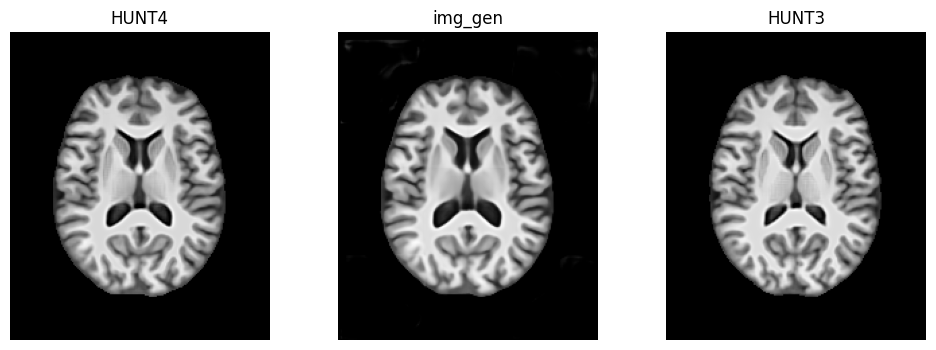

-------- Checkpoint: 15
ID: 302


100%|██████████| 8/8 [01:29<00:00, 11.18s/it]


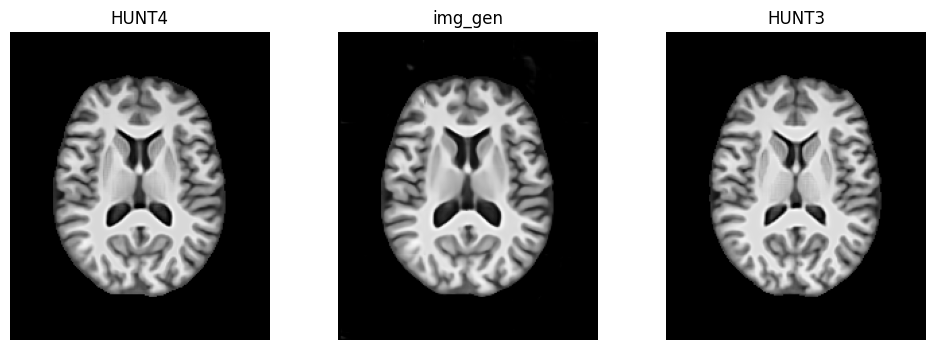

In [9]:
# %matplotlib widget
current_plane = 116

matching_ids = pil.get_matching_ids()
id_indexs = [302]
images_list = []
for checkpoint_index in [14,15]:
    print(f"-------- Checkpoint: {checkpoint_index}")
    checkpoint.restore(f"{checkpoint_dir}/ckpt-{checkpoint_index}")
    for id_index in id_indexs:
        print(f"ID: {id_index}")
        id = matching_ids[id_index]
        
        img_hunt3, img_hunt4, img_gen = generate_image(id, G, patch_size=(64,64,64), patch_step=(32,32,32))

        vis.shows_3_images(img_hunt3, img_hunt4, img_gen)
        # fc.imgshow_3D("img_gen", img_gen)
        # vis.show_rg_img(img_hunt4, img_gen, "HUNT4 vs Generated")
        images_list.append([img_hunt3, img_hunt4, img_gen])

        # save image
        # save_image(id, img_gen, checkpoint_index)




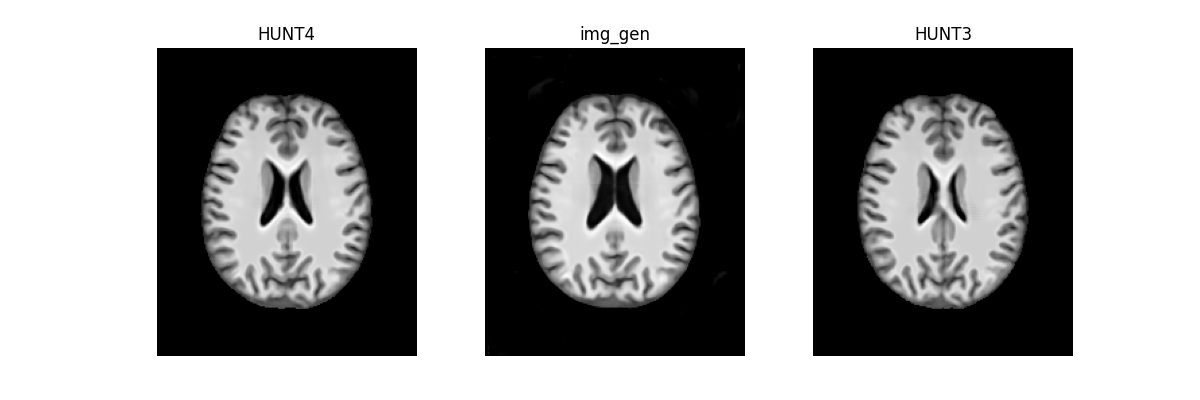

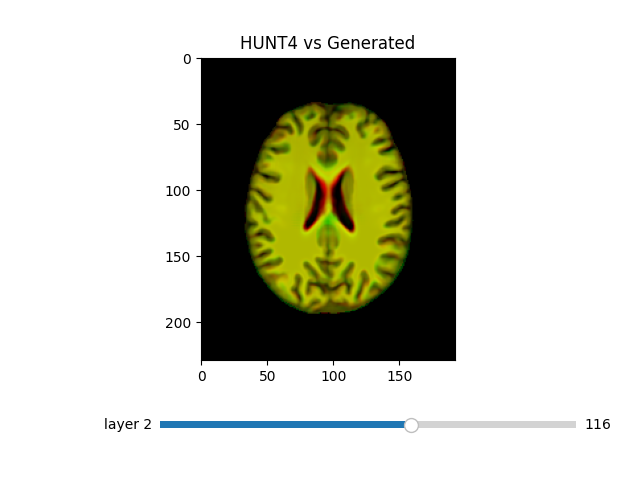

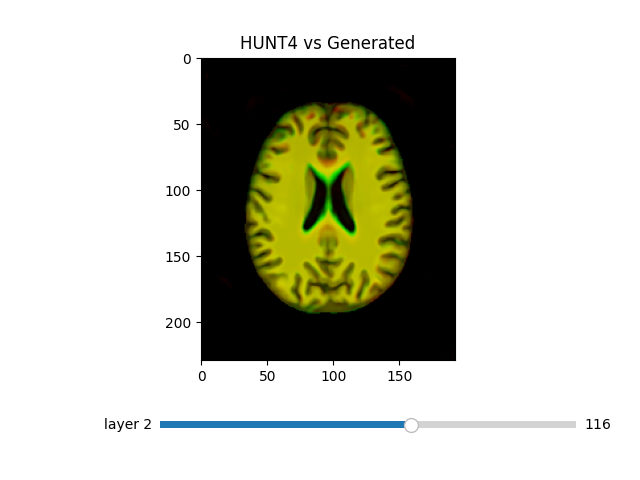

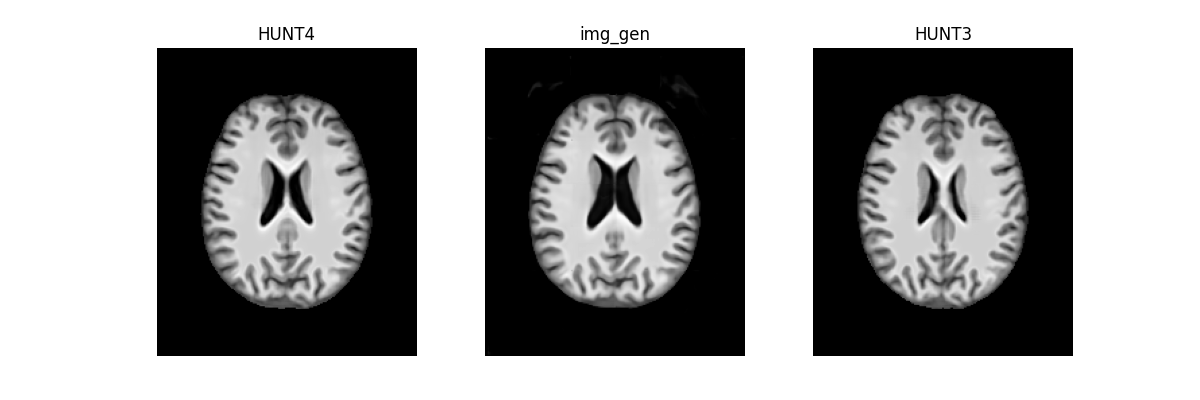

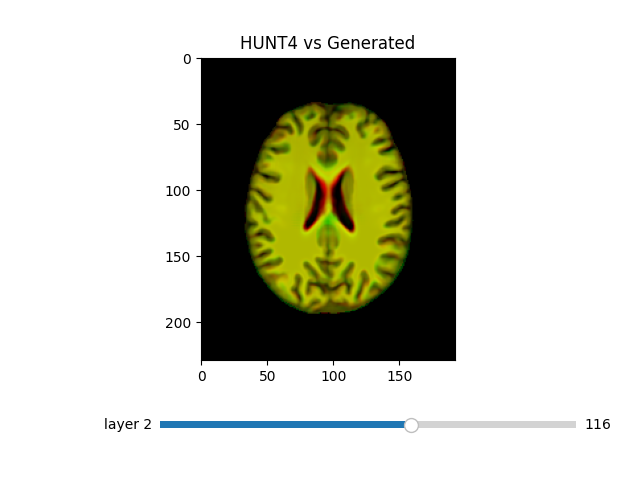

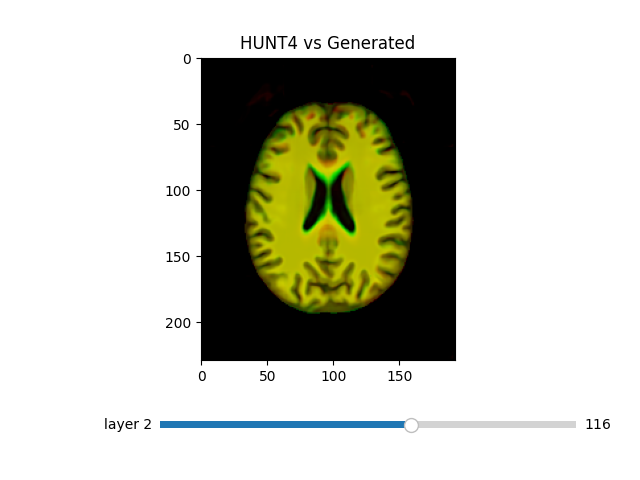

In [13]:
%matplotlib widget
for images in images_list:
    img_hunt3, img_hunt4, img_gen = images
    vis.shows_3_images(img_hunt3, img_hunt4, img_gen, current_plane=116)
    vis.show_rg_img(img_hunt3,img_hunt4, "HUNT4 vs Generated")
    vis.show_rg_img(img_gen,img_hunt4, "HUNT4 vs Generated")

